# Predictive maintenance on ESP32 edge telemetry

This notebook uses the CSV logged by the **Industrial Edge Monitor** firmware: 1,000 readings of temperature, humidity and vibration intensity, with the device's own risk score and alarm level. It asks three questions:

1. Can an **unsupervised** model (Isolation Forest) find the abnormal readings without being told which ones they are?
2. Can a **supervised** model learn the alarm level and risk score from the raw sensor values?
3. Which sensors drive the decisions?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest, RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("../data/industrial_dataset.csv")
df = pd.read_csv(DATA)
print(df.shape)
df.head()

(1000, 6)


,Time,Temp,Humidity,VibrationIntensity,Risk,Level
0,0,25.83,59.55,14,60,CRITICAL
1,1,21.96,63.35,3,0,NORMAL
2,2,26.44,56.68,0,8,NORMAL
3,3,25.31,53.43,4,1,NORMAL
4,4,26.50,65.63,1,8,NORMAL


In [2]:
df.describe().round(2)

,Time,Temp,Humidity,VibrationIntensity,Risk
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,499.50,26.88,59.84,2.86,15.87
std,288.82,3.90,4.87,3.68,24.44
min,0.00,20.31,45.75,0.00,0.00
25%,249.75,24.72,56.60,1.00,0.00
50%,499.50,26.16,60.07,2.00,8.00
75%,749.25,27.69,62.97,3.00,17.00
max,999.00,44.92,75.05,19.00,100.00


In [3]:
df["Level"].value_counts()

Level
NORMAL      890
CRITICAL    110
Name: count, dtype: int64

## 1. Unsupervised anomaly detection (Isolation Forest)
The model sees only the sensor values and the risk score, not the alarm labels. The labels are used afterwards to check how well the anomalies it finds match the firmware's alarms.

In [4]:
X_if = df[["Temp", "Humidity", "VibrationIntensity", "Risk"]]
iso = IsolationForest(n_estimators=100, contamination=0.1, random_state=42).fit(X_if)
df["Anomaly"] = (iso.predict(X_if) == -1).astype(int)
pd.crosstab(df["Level"], df["Anomaly"], rownames=["Firmware level"], colnames=["Isolation Forest anomaly"])

Isolation Forest anomaly,0,1
Firmware level,,
CRITICAL,12,98
NORMAL,888,2


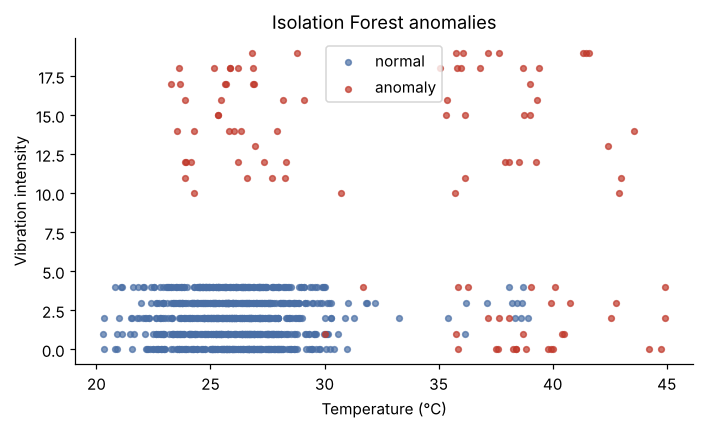

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for flag, colour, label in [(0, "#4a6fa5", "normal"), (1, "#c0392b", "anomaly")]:
    s = df[df["Anomaly"] == flag]
    ax.scatter(s["Temp"], s["VibrationIntensity"], s=14, alpha=0.7, c=colour, label=label)
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Vibration intensity"); ax.set_title("Isolation Forest anomalies")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Supervised models: alarm level and risk score

In [6]:
X = df[["Temp", "Humidity", "VibrationIntensity"]]
y_level = (df["Level"] == "CRITICAL").astype(int)   # explicit encoding: 1 = CRITICAL
y_risk = df["Risk"]
X_tr, X_te, yl_tr, yl_te, yr_tr, yr_te = train_test_split(X, y_level, y_risk, test_size=0.2, random_state=42, stratify=y_level)

clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_tr, yl_tr)
print(classification_report(yl_te, clf.predict(X_te), target_names=["NORMAL", "CRITICAL"]))
print(confusion_matrix(yl_te, clf.predict(X_te)))

reg = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_tr, yr_tr)
pred = reg.predict(X_te)
print(f"Risk score  MAE = {mean_absolute_error(yr_te, pred):.3f}   R² = {r2_score(yr_te, pred):.4f}")

              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00       178
    CRITICAL       1.00      1.00      1.00        22

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

[[178   0]
 [  0  22]]


Risk score  MAE = 0.266   R² = 0.9978


Near-perfect scores are expected. The firmware sets the alarm level and the risk score **from these same sensor values using fixed rules**, so the models are relearning that rule set. The value of this step is that it is a ready-made template: when the device logs real failure labels (bearing wear, overheating shutdowns), the same code trains a genuine predictive model.

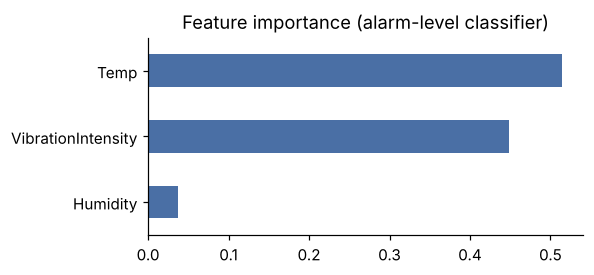

In [7]:
imp = pd.Series(clf.feature_importances_, index=X.columns).sort_values()
ax = imp.plot.barh(figsize=(5.5, 2.6), color="#4a6fa5"); ax.set_title("Feature importance (alarm-level classifier)")
plt.tight_layout(); plt.show()

## 3. Scoring a new reading

In [8]:
def predict_machine(temp, humidity, vibration):
    x = pd.DataFrame([[temp, humidity, vibration]], columns=X.columns)
    level = "CRITICAL" if clf.predict(x)[0] == 1 else "NORMAL"
    return level, round(float(reg.predict(x)[0]), 1)

for reading in [(26, 55, 0), (29, 60, 12), (35, 60, 18)]:
    print(reading, "->", predict_machine(*reading))

(26, 55, 0) -> ('NORMAL', 5.0)
(29, 60, 12) -> ('CRITICAL', 69.4)
(35, 60, 18) -> ('CRITICAL', 100.0)


## 4. Export
The labelled file feeds the AI report generator in `ml/ai_report.py`.

In [9]:
out = Path("output_with_anomalies.csv"); df.to_csv(out, index=False); print("saved", out)

saved output_with_anomalies.csv
